In [1]:
%matplotlib ipympl

In [2]:
import mlflow
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import linregress

from benchmark.config import EXPERIMENT_NAME
from benchmark.prompt import CONFIDENCE_TOLERANCE


In [3]:
exp = mlflow.set_experiment("confidence")

In [55]:
# one row per child run (a model x system-prompt pair) with each scorer's
# mean over the run; the model is only recorded in the run name. The
# per-trace "<scorer>/by_price_time" series only show their last point in a
# runs table, so they are left out.
run_name = "sweep-20261103-1400"
# the parentRunId tag holds the parent's run_id, not its name, so look the
# parent up by name first
parent = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.runName = '{run_name}'",
)
# assert len(parent) == 1, f"expected one run named {run_name!r}, found {len(parent)}"
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent.run_id.iloc[0]}'",
)

In [56]:
# every trace (one per predict call) of every child run, tagged with the run
# it came from. The record's inputs sit under request["inputs"], the market
# category is a tag copied onto the trace, and each scorer's value is an
# assessment on the trace.
traces = pd.concat(
    [
        mlflow.search_traces(locations=[exp.experiment_id], run_id=run_id).assign(
            run=name
        )
        for run_id, name in zip(runs["run_id"], runs["tags.mlflow.runName"])
    ],
    ignore_index=True,
)

In [57]:
def assessment_value(assessments: list, name: str) -> float | None:
    # scorer outputs are stored as "feedback", dataset expectations (the
    # market's own probability) as "expectation"
    for a in assessments:
        if a["assessment_name"] == name:
            return (a.get("feedback") or a["expectation"])["value"]
    return None


In [58]:
trace_df_raw = pd.DataFrame(
    {
        "run": traces["run"],
        "model": traces["request"].map(lambda r: r["model"]),
        "system_prompt": traces["request"].map(lambda r: r["system_prompt"]),
        # a tag on the child run rather than on the trace, as "YYYY-MM"; taken
        # as the last day of that month so it compares against as_of
        "training_data_cutoff": pd.PeriodIndex(
            traces["run"].map(
                dict(
                    zip(runs["tags.mlflow.runName"], runs["tags.training_data_cutoff"])
                )
            ),
            freq="M",
        )
        .to_timestamp(how="end")
        .normalize(),
        "exchange": traces["tags"].map(lambda t: t.get("exchange")),
        "category": traces["tags"].map(lambda t: t.get("event_category")),
        "event_type": traces["tags"].map(lambda t: t.get("std_event_type")),
        "market_title": traces["request"].map(lambda r: r["inputs"]["market_title"]),
        "response": traces["response"].map(lambda r: r and r["raw"]),
        "as_of": traces["request"].map(lambda r: pd.Timestamp(r["inputs"]["as_of"])),
        "predicted_probability": traces["response"].map(
            lambda r: r and r["probability"]
        ),
        # the model's probability that its estimate is within
        # CONFIDENCE_TOLERANCE of the market price; absent in older runs
        "confidence": traces["response"].map(lambda r: r and r.get("confidence")),
        "market_probability": traces["assessments"].map(
            lambda a: assessment_value(a, "market_probability")
        ),
        "state": traces["state"],
    }
)
trace_df = trace_df_raw[trace_df_raw["system_prompt"] == "cutoff"]
trace_df = trace_df[trace_df["as_of"] > pd.Timestamp("2026-06-30")]

In [60]:
trace_df["error"] = abs(
    trace_df["market_probability"] - trace_df["predicted_probability"]
)

In [61]:
# whether the forecast was "correct" in the sense the model was asked to
# rate: within CONFIDENCE_TOLERANCE of the market price
trace_df["within_tolerance"] = trace_df["error"] <= CONFIDENCE_TOLERANCE


In [62]:
# Brier score of the model's confidence against whether it was in fact
# within tolerance; 0.25 is what a constant 0.5 confidence would score
trace_df["confidence_brier"] = (
    trace_df["confidence"] - trace_df["within_tolerance"]
) ** 2


In [63]:
trace_df[
    [
        "event_type",
        "market_title",
        "response",
        "as_of",
        "error",
        "predicted_probability",
        "market_probability",
        "confidence",
        "within_tolerance",
    ]
]

,event_type,market_title,response,as_of,error,predicted_probability,market_probability,confidence,within_tolerance
0,corporate KPI,Will Colgate-Palmolive (CL) beat quarterly ear...,"Looking at this question, I need to estimate t...",2026-10-17 00:00:51,0.0800,0.62,0.7000,0.52,True
1,None,Will legislation that increases the statutory ...,"# Analyzing the Debt Limit Market (Kalshi, ope...",2026-10-30 04:00:00,0.0200,0.03,0.0100,0.75,True
2,election,Will Grant William Bedard win the 2026 Kingsto...,"Looking at this market, I need to assess what ...",2026-08-25 00:00:12,0.0205,0.03,0.0505,0.55,True
3,commodity price,Euro / US Dollar (EUR/USD) Up or Down on Novem...,"Looking at this question, I need to assess the...",2026-10-31 00:00:54,0.0000,0.50,0.5000,0.90,True
4,None,Russell 2000 (RUT) Up or Down on September 14?,"# Estimating the Opening Price for ""Russell 20...",2026-09-12 00:00:20,0.1850,0.52,0.3350,0.55,False
...,...,...,...,...,...,...,...,...,...
195,election,Colorado passes ballot measure imposing life s...,"Looking at this question, I need to estimate t...",2026-07-22 00:00:09,0.4200,0.92,0.5000,0.55,False
196,social media post,Will Zelenskyy post 0-19 posts from October 23...,"Looking at this market, I need to estimate the...",2026-10-21 00:00:20,0.0250,0.07,0.0950,0.45,True
197,None,Will average **gas prices** be above $4.0550?,"Looking at this market, I need to assess the l...",2026-10-27 04:00:00,0.4100,0.07,0.4800,0.35,False
198,unknown,Will the White House call a full lid by 6:30 P...,"Looking at this market, I need to consider:\n\...",2026-11-01 06:32:14,0.1500,0.65,0.5000,0.30,False


In [64]:
# calibration headline: mean confidence should match the hit rate
trace_df.groupby("model")[["confidence", "within_tolerance", "confidence_brier"]].mean()


,confidence,within_tolerance,confidence_brier
model,,,
claude-opus-4-6,0.4751,0.465,0.229841


In [65]:
# calibration curve: hit rate per confidence decile against the bin midpoint
calibration = (
    trace_df.dropna(subset=["confidence"])
    .assign(bin=lambda d: pd.cut(d["confidence"], bins=10, labels=False))
    .groupby(["model", "bin"])
    .agg(
        confidence=("confidence", "mean"),
        hit_rate=("within_tolerance", "mean"),
        n=("confidence", "size"),
    )
    .reset_index()
)


Text(0, 0.5, 'share within 0.1 of market')

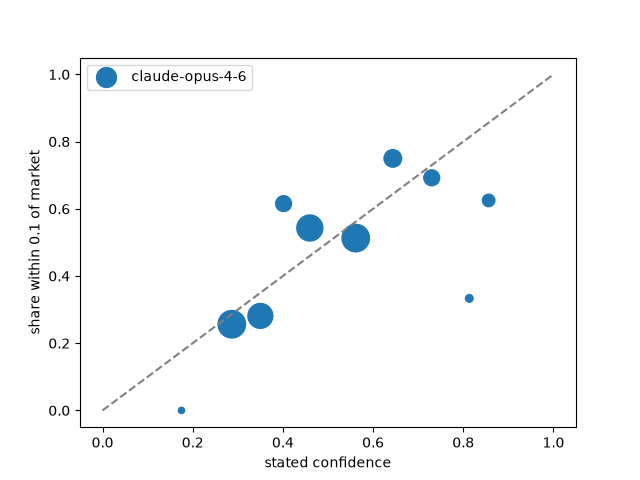

In [66]:
cal_ax = None
for i, (model, points) in enumerate(calibration.groupby("model")):
    cal_ax = points.plot.scatter(
        x="confidence",
        y="hit_rate",
        s=points["n"] * 10,
        label=model,
        color=f"C{i}",
        ax=cal_ax,
    )
cal_ax.plot([0, 1], [0, 1], color="grey", linestyle="--")
cal_ax.set_xlabel("stated confidence")
cal_ax.set_ylabel(f"share within {CONFIDENCE_TOLERANCE} of market")


In [67]:
trace_df["error"].hist(bins=20, figsize=(8, 4))

<Axes: xlabel='stated confidence', ylabel='share within 0.1 of market'>

In [68]:
# months from the model's training cutoff to the market price time, positive
# when the market was priced after the cutoff (fractional: days / mean month)
trace_df["time_diff"] = (
    trace_df["as_of"] - trace_df["training_data_cutoff"]
).dt.days / (365.25 / 12)


Text(0.5, 0, 'months after training cutoff')

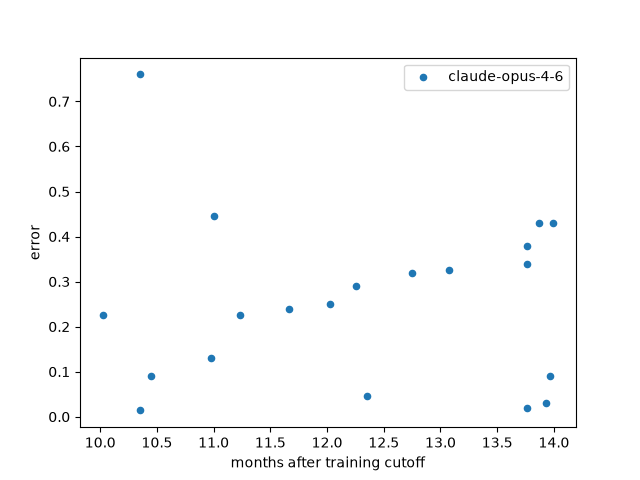

In [49]:
# one series per model so the legend says which model each point is
ax = None
for i, (model, points) in enumerate(trace_df.groupby("model")):
    ax = points.plot.scatter(
        x="time_diff", y="error", label=model, color=f"C{i}", ax=ax
    )
ax.set_xlabel("months after training cutoff")

In [50]:
# rows whose forecast could not be parsed have no error and would make the
# fit NaN
scored = trace_df.dropna(subset=["error"])


In [51]:
fit = smf.ols("error ~ time_diff + C(model)", data=scored).fit()


In [52]:
fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  error   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.054
Method:                 Least Squares   F-statistic:                   0.03196
Date:                Tue, 03 Nov 2026   Prob (F-statistic):              0.860
Time:                        13:37:24   Log-Likelihood:                 5.6653
No. Observations:                  20   AIC:                            -7.331
Df Residuals:                      18   BIC:                            -5.339
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3212      0.379      0.848      0.408      -0.475       1.117
time_diff     -0.0055      0.031     -0.179      0.860      -0.070       0.059
==============================================================================
Omnibus:                        3.594   Durbin-Watson:                   1.577
Prob(Omnibus):                  0.166   Jarque-Bera (JB):                1.904
Skew:                           0.719   Prob(JB):                        0.386
Kurtosis:                       3.468   Cond. No.                         110.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [53]:
# the same fit per model, slope in error per month with its p-value
by_model = scored.groupby("model").apply(
    lambda g: pd.Series(linregress(g["time_diff"], g["error"])._asdict()),
    include_groups=False,
)


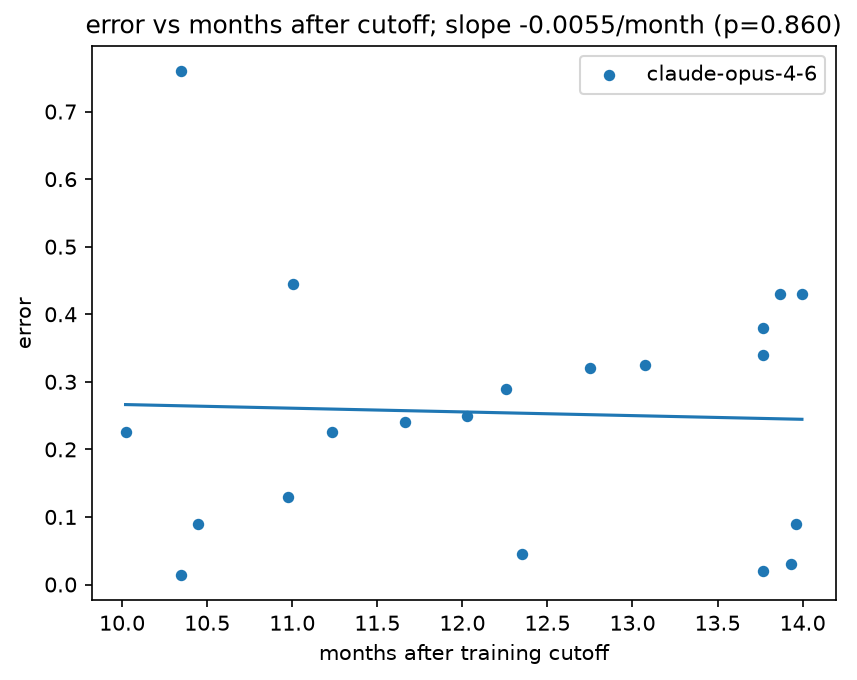

In [54]:
# the fitted line per model: common slope, model-specific intercept
for i, (model, points) in enumerate(scored.groupby("model")):
    x = points["time_diff"].sort_values()
    ax.plot(
        x,
        fit.predict(pd.DataFrame({"time_diff": x, "model": model})),
        color=f"C{i}",
    )
ax.set_title(
    f"error vs months after cutoff; slope {fit.params['time_diff']:.4f}/month (p={fit.pvalues['time_diff']:.3f})"
)
ax.figure
